# $\log3$: historical CMF construction

Exact rational CMF approximants, with $\delta_N=-1-\log|\log3-p_N/q_N|/\log q_N$.
Published asymptotic bounds and measured finite-depth exponents are kept separate.


In [ ]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy


## Setup

Keep `cmfs.py` next to this notebook.


In [ ]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from cmfs import huttner_logs, huttner_logs_seeds, salikhov_log3, salikhov_log3_seeds

sys.set_int_max_str_digits(0)
results = {}


def delta(approximant):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(3*q.bit_length() + 256):
        error = abs(arb(3).log() - arb(p)/q)
        assert error > 0
        return float((-1 - error.log()/arb(q).log()).mid())

from cmfs import RhinLog3CMF, rhin_log3_seeds


## 1. Huttner (2003): $\log 3$ from the simultaneous construction

[Corollary 3.1(4), pp. 146–147](https://www.jstage.jst.go.jp/article/kyushujm/57/1/57_1_129/_pdf)
gives a linear-independence exponent $10.1017577\ldots$ for $1,\log2,\log3$.
It implies $\mu(\log 3)\le11.1017577\ldots$, with comparison scale
$\delta_{\rm eq}=1/10.1017577\ldots\approx0.09899267$.

The source integrals are
$$R_{i,n}=\int_{I_i}\frac{[t(t-\tfrac12)(t-\tfrac13)]^{2n}}{(t-1)^{3n}}\,dt,
\quad I_1=[0,\tfrac13],\quad I_2=[\tfrac13,\tfrac12].$$
With $z=1-t$, their common CMF transports the moments of
$$(z-1)^u(z-\tfrac23)^v(z-\tfrac12)^w z^{-m}.$$
This is a **rank-three, four-axis** field on $(u,v,w,m)$, with start
$(2,2,2,3)$ and direction $(2,2,2,3)$. Source index $n$ uses exactly $n-1$ steps.

Let $P_{32},P_{43},Q$ be the seed rows obtained by Laurent integration at
$n=1$. The individual readouts are $(P_{32}W)_0/(QW)_0$ for $\log(3/2)$
and $(P_{43}W)_0/(QW)_0$ for $\log(4/3)$.
Since $\log 3=2\log(3/2)+\log(4/3)$, use
$$P=2P_{32}+P_{43},\qquad \frac{p_n}{q_n}=\frac{(PW_{n-1})_0}{(QW_{n-1})_0}.$$
This is another readout of the same historical simultaneous construction,
not an independent construction or a new record bound.

The reduced-rational $\delta_n$ need not equal $\delta_{\rm eq}$:
the theorem bounds all integer linear forms, whereas reduction can remove
additional factors from a particular scalar approximant's denominator.
All three moment coefficient pairs were checked by exact source integration
at $n=1,\ldots,7$; all six axis pairs were checked at two regular points.
The source-index-1000 error was computed with overlapping Arb intervals at
two precisions. Supporting scripts and reports remain in ignored `local_checks/`.


In [5]:
u, v, w, m = sp.symbols("u v w m")
cmf = huttner_logs()
start = {u: 2, v: 2, w: 2, m: 3}
trajectory = {u: 2, v: 2, w: 2, m: 3}
depths = list(range(10, 1001, 10))  # source indices
P, Q = huttner_logs_seeds(3)
walks = cmf.walk(trajectory, [N - 1 for N in depths], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]
deltas = [delta(r) for r in approximants]
results["Huttner (2003), simultaneous"] = (depths, deltas)
print(f"delta at source index 1000: {deltas[-1]:.15f}")


delta at source index 1000: 0.100280814170708


## 2. Salikhov (2007): symmetric integral construction

[Salikhov, *On the irrationality measure of ln 3*, Doklady Mathematics 76 (2007), 955–957](https://doi.org/10.1134/S1064562407060361)
establishes $\mu(\log3)\le5.125$. The integral formula below is explicitly
reproduced in the introduction of
[Wu–Wang (2014)](https://doi.org/10.1016/j.jnt.2014.03.007), which is the
formula source used for this recovery; the full 2007 article was not accessible.
The 2007 bound is also confirmed in the introduction of
[Bondareva–Luchin–Salikhov (2018)](https://www.mathnet.ru/php/getFT.phtml?jrnid=cheb&option_lang=rus&paperid=619&what=fullt).
Its comparison exponent is $\delta_{\rm eq}=1/(5.125-1)=0.24242424\ldots$.

For $h=5,7$, set
$$I_{h,n}=\int_{35}^{35+h}
\frac{[(x-28)(x-30)(x-35)^2(x-40)(x-42)]^n}
{[x(70-x)]^{2n+1}}\,dx.$$
Writing $r=x-35$ and $y=r^2$ gives
$$I_{h,n}=\frac12\int_0^{h^2}
\frac{y^{n-1/2}(y-25)^n(y-49)^n}{(1225-y)^{2n+1}}\,dy.$$
Thus the full moment CMF of $y^u(y-25)^v(y-49)^w(1225-y)^{-m}$ has
**rank 3 and four independent axes** $(u,v,w,m)$, with start
$(-1/2,0,0,1)$ and direction $(1,1,1,2)$. Source index $n$ is exactly
the number of CMF steps.

Use the original $r$-moments, whose common factor $1/2$ cancels in the readout.
At $n=0$ their rows are
$$C_h=(0,-h,-h^3/3-1225h),\qquad
B=\frac1{70}(1,1225,1225^2),$$
with moment vector $C_h+B\log((35+h)/(35-h))$.
Since $2\log(3/2)+\log(4/3)=\log3$, the exact readout is
$$P=-(2C_7+C_5),\quad Q=B,\qquad
\frac{p_n}{q_n}=\frac{(PW_n)_0}{(QW_n)_0}.$$

Independent partial-fraction integration checks every moment coefficient
at $n=0,1,2,3$ for both endpoints. All six axis pairs pass at two regular
points. The source-index-1000 error is checked with overlapping Arb intervals
at two precisions. These checks recover the rational forms; the arithmetic
argument establishing the published measure bound is taken from the literature.


In [7]:
u, v, w, m = sp.symbols("u v w m")
cmf = salikhov_log3()
start = {u: -sp.Rational(1, 2), v: 0, w: 0, m: 1}
trajectory = {u: 1, v: 1, w: 1, m: 2}
depths = list(range(10, 1001, 10))  # source n equals walk length
P, Q = salikhov_log3_seeds()
walks = cmf.walk(trajectory, depths, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]
deltas = [delta(r) for r in approximants]
results["Salikhov (2007)"] = (depths, deltas)
print(f"delta at source index 1000: {deltas[-1]:.15f}")


delta at source index 1000: 0.245429302711229


## 3. Rhin (1987): polynomial insertions and an integer staircase

Rhin's published bound is $\mu(\log3)<8.616$, also valid for every nonzero
rational combination of $\log2$ and $\log3$. The exact floor construction
used here is the reconstruction in
[Zudilin (2004), Section 3.4, equations (23)–(24)](https://arxiv.org/pdf/math/0404523),
which attributes it to Rhin, *Approximants de Padé et mesures effectives
d'irrationalité*, pp. 155–164 (1987).
Its comparison exponent is $1/(8.616-1)\approx0.13130252$.

Put
$$\begin{aligned}
(f_1,\ldots,f_6)={}&(z-1,z-\tfrac23,z-\tfrac43,5z-4,\\
&17z^2-34z+16,19z^2-36z+16),\\
\alpha={}&(0.704324,0.552418,0.447582,0.109072,0.038934,0.054368).
\end{aligned}$$
Up to the source's common scalar $2^{14}3^{2N+7}$, which cancels in the
rational readout, the two integrals are
$$J_{a,N}=\int_1^a z^{-N-1}\prod_{i=1}^6f_i(z)^{\lfloor\alpha_iN\rfloor}\,dz,
\qquad a\in\{2/3,4/3\}.$$
The full field has **rank 8 and seven independent axes** $(e_1,\ldots,e_6,b)$
for weight $z^{-b}\prod f_i^{e_i}$. Start at $(0,\ldots,0,1)$ and end at
$(\lfloor\alpha_1N\rfloor,\ldots,\lfloor\alpha_6N\rfloor,N+1)$.
Thus $N$ is the source index, not the number of elementary axis shifts.
`RhinLog3CMF.walk` evaluates the full integration-by-parts axis matrices at
rational points, avoiding large symbolic expressions.

For the moment basis $1,z,\ldots,z^7$, define
$$C_a=(0,a-1,(a^2-1)/2,\ldots,(a^7-1)/7),\quad B=(1,0,\ldots,0).$$
Since $\log3=\log(4/3)-2\log(2/3)$, the exact readout is
$$P=2C_{2/3}-C_{4/3},\quad Q=B,\qquad
\frac{p_N}{q_N}=\frac{(PW_N)_0}{(QW_N)_0}.$$

All 21 axis pairs pass conservation checks at two regular points. Direct
Laurent integration of the source polynomial agrees with all eight transported
coefficient pairs at $N=1,\ldots,7$, and with the readout coefficients at
$N=10,100,1000$. The final error is checked with overlapping Arb intervals
at two precisions. Finite-depth $\delta_N$ is distinct from the asymptotic
measure bound, whose arithmetic proof is taken from the literature.


In [9]:
cmf = RhinLog3CMF()
axes = cmf.axes
start = dict(zip(axes, [0]*6 + [1]))
slopes = (704324, 552418, 447582, 109072, 38934, 54368)
trajectory = dict(zip(axes, [sp.Rational(a, 1000000) for a in slopes] + [sp.S.One]))
depths = list(range(10, 1001, 10))  # exact source indices, floors applied by walk
P, Q = rhin_log3_seeds()
walks = cmf.walk(trajectory, depths, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]
deltas = [delta(r) for r in approximants]
results["Rhin (1987)"] = (depths, deltas)
print(f"delta at source index 1000: {deltas[-1]:.15f}")


delta at source index 1000: 0.133378810392054


## All constructions


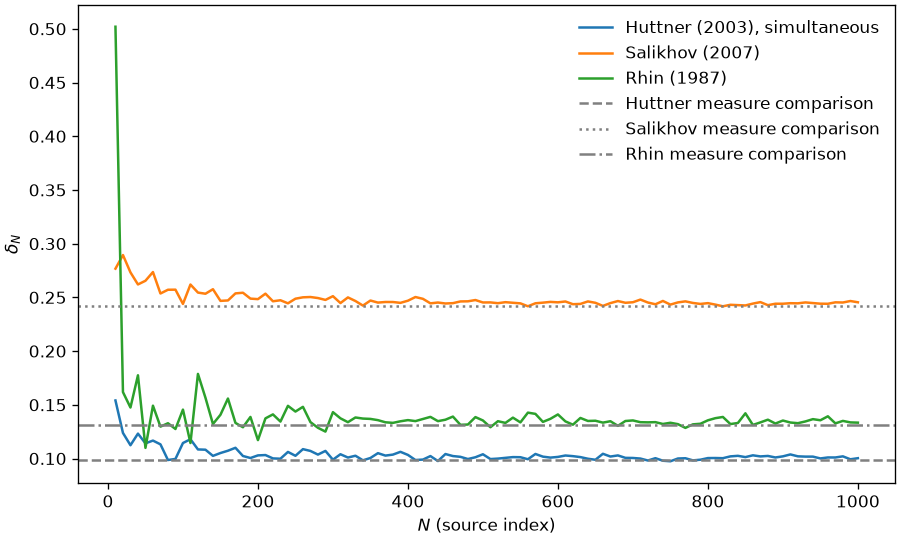

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.axhline(1/10.1017577, color="gray", linestyle="--", label="Huttner measure comparison")
ax.axhline(1/(5.125-1), color="gray", linestyle=":", label="Salikhov measure comparison")
ax.axhline(1/(8.616-1), color="gray", linestyle="-.", label="Rhin measure comparison")
ax.set(xlabel="$N$ (source index)", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()


## Historical overview

| Construction | Published upper bound $\mu_0$ | Comparison $\delta_{\rm eq}$ | Verified $\delta_{1000}$ |
|:--|--:|--:|--:|
| Huttner (2003), simultaneous | $11.1017577\ldots$ | $0.09899267$ | $0.100280814171$ |
| Salikhov (2007) | $5.125$ | $0.24242424$ | $0.245429302711$ |
| Rhin (1987) | $8.616$ | $0.13130252$ | $0.133378810392$ |

This notebook recovers three historical constructions; it is not an exhaustive list or a claim of the best known bound.
